# Fitting Gaia epoch astrometry with `gaiamock`

This notebook generates mock Gaia epoch astrometry for an astrometric binary, fits an orbit, and plots the diagnostics. It also compares the available nonlinear optimizers:

- `periodogram_multistart_v2`: the default. It searches a frequency-based periodogram, then refines multiple circular and eccentric starts, including neighboring frequencies, harmonics, and long-period anchors.
- `periodogram_multistart`: the previous periodogram search, now using the faster χ² evaluator.
- `periodogram_multistart_full`: the previous strategy with a denser period grid and tighter local tolerances.
- `periodogram_multistart_gsl`: the previous search with the original GSL χ² evaluator, retained for comparison.
- `multistart`: the deterministic C grid/multistart search without periodogram preselection.
- `annealing`: the original adaptive simulated annealing search described in the gaiamock paper.


## Setup

Install gaiamock with `pip install gaiamock`, or install the development version with `pip install -e .` from the top of this repository. Binary wheels include GSL; building the C library from source requires GSL (see the README). If you update a source checkout, reinstall it to rebuild `kepler_solve_astrometry.so`, then restart the notebook kernel.

The mock-data generator also needs the precomputed Gaia scanning law (`healpix_scans/`). Download it once by running `gaiamock-download` in a terminal. If you already have it elsewhere, set `GAIAMOCK_DATA_DIR` to the directory containing `healpix_scans/` before starting the kernel.


In [1]:
from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt

import gaiamock

GAIAMOCK_DIR = Path(gaiamock.__file__).resolve().parent
c_funcs = gaiamock.read_in_C_functions()

print(f"Using gaiamock from: {Path(gaiamock.__file__).resolve()}")
print(f"Using C library from: {GAIAMOCK_DIR / 'kepler_solve_astrometry.so'}")

HEALPIX_DIR = gaiamock.data_path("healpix_scans")  # raises FileNotFoundError if you haven't run gaiamock-download
print(f"Using healpix scans from: {HEALPIX_DIR}")


Using gaiamock from: /Users/kareem/Proposals/gaia/bhs/scratch/gaiamock_optimizer_improvement_20261115/gaiamock_pr/src/gaiamock/__init__.py
Using C library from: /Users/kareem/Proposals/gaia/bhs/scratch/gaiamock_optimizer_improvement_20261115/gaiamock_pr/src/gaiamock/kepler_solve_astrometry.so
Using healpix scans from: /Users/kareem/bin/gaiamock/healpix_scans


## Generate mock Gaia epoch astrometry

`gaiamock.predict_astrometry_binary_in_terms_of_a0` generates Gaia-like one-dimensional along-scan astrometry for a binary. It uses the precomputed Gaia scanning law samples in `healpix_scans/`, then adds noise using the approximate Gaia along-scan uncertainty model.

The returned arrays are exactly the inputs expected by the fitters:

- `t_ast_yr`: epoch times in years relative to the Gaia reference epoch.
- `psi`: scan angles in radians.
- `plx_factor`: along-scan parallax factors.
- `ast_obs`: along-scan astrometric measurements in mas.
- `ast_err`: uncertainties in mas.

In [2]:
# Reproducibility for the mocked noise and random epoch rejection.
np.random.seed(11)

mock_truth = {
    "ra": 280.0,                 # deg
    "dec": 35.0,                # deg
    "parallax": 0.55,           # mas
    "pmra": 0.03,               # mas/yr
    "pmdec": -0.02,             # mas/yr
    "period": 255.0,            # days
    "Tp": 2.0,                  # days relative to the Gaia reference epoch convention used internally
    "ecc": 0.08,
    "omega": 1.1,               # big Omega, radians
    "inc": np.deg2rad(67.0),    # radians
    "w": 0.8,                   # little omega, radians
    "a0_mas": 1.20,             # photocenter semimajor axis, mas
    "phot_g_mean_mag": 16.0,
    "data_release": "dr4",
}

# This is the gaiamock mock-data generator. It returns epoch astrometry arrays.
t_ast_yr, psi, plx_factor, ast_obs, ast_err = gaiamock.predict_astrometry_binary_in_terms_of_a0(
    c_funcs=c_funcs,
    **mock_truth,
)

# Sort by time and remove any non-finite values, just as you would for real data.
good = np.isfinite(t_ast_yr) & np.isfinite(psi) & np.isfinite(plx_factor) & np.isfinite(ast_obs) & np.isfinite(ast_err) & (ast_err > 0)
order = np.argsort(t_ast_yr[good])
t_ast_yr, psi, plx_factor, ast_obs, ast_err = [arr[good][order] for arr in (t_ast_yr, psi, plx_factor, ast_obs, ast_err)]

print(f"N_epoch = {len(t_ast_yr)}")
print("Mock truth:")
for key in ("period", "Tp", "ecc", "a0_mas", "parallax", "phot_g_mean_mag"):
    print(f"  {key:16s} {mock_truth[key]}")

N_epoch = 88
Mock truth:
  period           255.0
  Tp               2.0
  ecc              0.08
  a0_mas           1.2
  parallax         0.55
  phot_g_mean_mag  16.0


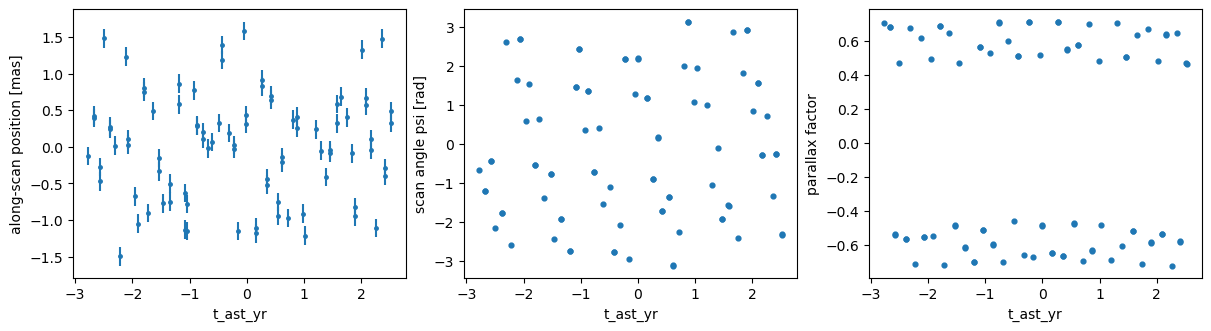

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), constrained_layout=True)
axes[0].errorbar(t_ast_yr, ast_obs, yerr=ast_err, fmt=".", ms=5)
axes[0].set_xlabel("t_ast_yr")
axes[0].set_ylabel("along-scan position [mas]")
axes[1].scatter(t_ast_yr, psi, s=12)
axes[1].set_xlabel("t_ast_yr")
axes[1].set_ylabel("scan angle psi [rad]")
axes[2].scatter(t_ast_yr, plx_factor, s=12)
axes[2].set_xlabel("t_ast_yr")
axes[2].set_ylabel("parallax factor")
plt.show()

## First: fit a 5-parameter single-star model

`check_ruwe` fits the usual five astrometric parameters and returns a RUWE-like goodness of fit. A large value is a sign that a single-star model is not adequate.

In [4]:
ruwe_5p, mu_5p, sigma_mu_5p = gaiamock.check_ruwe(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    binned=True,
)

single_star_names = ["ra_off", "pmra", "dec_off", "pmdec", "plx"]
print(f"5p RUWE-like statistic: {ruwe_5p:.3f}")
for name, value, err in zip(single_star_names, mu_5p, sigma_mu_5p):
    print(f"{name:7s} = {value:9.4f} +/- {err:.4f}")

5p RUWE-like statistic: 2.010
ra_off  =   -0.1380 +/- 0.0375
pmra    =    0.0340 +/- 0.0246
dec_off =   -0.0713 +/- 0.0408
pmdec   =    0.0336 +/- 0.0257
plx     =    0.5031 +/- 0.0464


## Compare the nonlinear orbit optimizers directly

The orbital model is linear in the five astrometric and four Thiele-Innes parameters for fixed nonlinear parameters `(P, phi_p, ecc)`. The optimizer searches only those three nonlinear parameters; each trial evaluates the best linear least-squares fit. The fast χ² evaluator projects out the fixed astrometric columns once per source and updates the orbital projection for each trial.

The direct optimizer returns only `(P, phi_p, ecc)`. We then call `get_astrometric_chi2` to recover χ² and the linear parameters.

Omitting `optimizer`, passing `None`, or passing `"default"` selects **`periodogram_multistart_v2`**. The first row below deliberately omits the argument. Pass `optimizer="periodogram_multistart"` to reproduce the previous search strategy.

All methods below use `reject_outlier=True`: they minimize the objective with the single worst epoch removed at each trial. Keep this setting the same when comparing methods. Timings are illustrative single fits and depend on the machine and C build.


In [5]:
def run_direct_optimizer(label, optimizer=None, reject_outlier=True, p_min=10.0, p_max=1e4):
    kwargs = {}
    if optimizer is not None:
        kwargs["optimizer"] = optimizer

    start = time.monotonic()
    theta = gaiamock.fit_orbital_solution_nonlinear(
        t_ast_yr,
        psi,
        plx_factor,
        ast_obs,
        ast_err,
        c_funcs,
        L=np.array([p_min, 0.0, 0.0]),
        U=np.array([p_max, 2 * np.pi, 0.99]),
        reject_outlier=reject_outlier,
        **kwargs,
    )
    seconds = time.monotonic() - start
    chi2, mu_linear = gaiamock.get_astrometric_chi2(
        t_ast_yr,
        psi,
        plx_factor,
        ast_obs,
        ast_err,
        P=theta[0],
        phi_p=theta[1],
        ecc=theta[2],
        c_funcs=c_funcs,
        reject_outlier=reject_outlier,
    )
    return {
        "optimizer": label,
        "optimizer_arg": optimizer,
        "period": float(theta[0]),
        "phi_p": float(theta[1]),
        "ecc": float(theta[2]),
        "chi2": float(chi2),
        "seconds": seconds,
        "mu_linear": mu_linear,
    }


optimizer_runs = [
    ("default / periodogram_multistart_v2", None),
    ("periodogram_multistart", "periodogram_multistart"),
    ("periodogram_multistart_full", "periodogram_multistart_full"),
    ("periodogram_multistart_gsl", "periodogram_multistart_gsl"),
    ("multistart", "multistart"),
    ("annealing", "annealing"),
]

direct_results = []
for label, optimizer in optimizer_runs:
    result = run_direct_optimizer(label, optimizer=optimizer, reject_outlier=True)
    direct_results.append(result)
    print(
        f"{label:36s} P={result['period']:10.4f} d  "
        f"e={result['ecc']:.4f}  chi2={result['chi2']:.3f}  "
        f"time={result['seconds']:.3f} s"
    )


default / periodogram_multistart_v2  P=  255.7648 d  e=0.0334  chi2=56.327  time=0.030 s
periodogram_multistart               P=  255.7648 d  e=0.0334  chi2=56.327  time=0.032 s
periodogram_multistart_full          P=  255.7648 d  e=0.0334  chi2=56.327  time=0.054 s
periodogram_multistart_gsl           P=  255.7648 d  e=0.0334  chi2=56.327  time=0.210 s
multistart                           P=  255.7648 d  e=0.0334  chi2=56.327  time=0.268 s
annealing                            P=  255.7648 d  e=0.0334  chi2=56.327  time=0.907 s


### What is different between the optimizers?

- **`periodogram_multistart_v2` (default)** samples frequency with spacing tied to the time baseline, selects distinct local periodogram minima, and adds neighboring frequencies, period harmonics, and anchors from one quarter of the baseline to the upper period bound. It refines the candidates in `(ln P, e cos phi_p, e sin phi_p)`, allowing phase to wrap and avoiding an undefined phase at zero eccentricity. This broader search helps recover eccentric orbits and periods comparable to the baseline.
- `periodogram_multistart` uses the previous log-spaced grids and eccentric phase scan, followed by Nelder-Mead in `(ln P, phi_p, ecc)`. It shares the fast χ² evaluator with v2 and costs about the same, but can miss minima that v2 finds.
- `periodogram_multistart_full` increases the previous search's grid density, start count, and local accuracy. Its search strategy differs from v2; it is not a guarantee of a better minimum.
- `periodogram_multistart_gsl` performs the same search as `periodogram_multistart`, using the original linear-solve code. This comparison isolates the χ² speedup. Tiny numerical differences can occasionally change the optimizer's path.
- `multistart` scans period, phase, and eccentricity grids without periodogram preselection, then refines multiple starts.
- `annealing` uses a stochastic adaptive search; it can take different paths on repeated runs.

No method guarantees the global minimum. A simple mock can give nearly identical solutions with all six methods; difficult sources may have distinct competing minima, especially near the eccentricity limit.


## Run the full astrometric cascade

`fit_full_astrometric_cascade` first checks whether a five-parameter model is good enough. If not, it can check acceleration models. If those are skipped or do not pass the cuts, it fits the full 12-parameter orbital model.

Here we use `skip_acceleration=True` to go directly to an orbit and `reject_outlier=True` to match the direct-fit comparison. The nonlinear optimizer defaults to **`periodogram_multistart_v2`**, so the example omits the optimizer argument.


In [6]:
result = gaiamock.fit_full_astrometric_cascade(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    c_funcs=c_funcs,
    verbose=True,
    show_residuals=False,
    binned=True,
    ruwe_min=1.25,
    skip_acceleration=True,
    reject_outlier=True,
    P_min=10,
)

result_names = [
    "plx", "sig_parallax", "A", "sig_A", "B", "sig_B", "F", "sig_F", "G", "sig_G",
    "period", "sig_period", "phi_p", "sig_phi_p", "ecc", "sig_ecc", "inc_deg",
    "a0_mas", "sigma_a0_mas", "N_visibility_periods", "N_obs", "F2", "ruwe",
]

print("\nCascade result:")
for name, value in zip(result_names, result):
    print(f"{name:20s} {value}")

found best-fit nonlinear parameters: [2.55764848e+02 2.48975891e+00 3.34440286e-02]
goodness_of_fit (F2) is low enough to pass DR3 cuts! F2: -0.5
a0_over_err is high enough to pass DR3 cuts! a0_over_err: 43.3
parallax over error is NOT high enough to pass DR3 cuts! parallax_over_error: 22.5
eccentricity error is low enough to pass DR3 cuts! ecc_error: 0.04

Cascade result:
plx                  0.5295745570453679
sig_parallax         0.023582299759950978
A                    -0.4990826571062075
sig_A                0.6081768683338222
B                    -1.1169329390157516
sig_B                0.14009922085179333
F                    0.5007843524641875
sig_F                0.6088807951607411
G                    -0.11073061036940982
sig_G                1.3548507666746827
period               255.76484772965514
sig_period           0.3608253835926046
phi_p                2.4897589060866414
sig_phi_p            1.2110148495636723
ecc                  0.03344402857230883
sig_ecc         

## Compare the 5p and 12p residuals

Plot the default v2 solution, comparing the single-star residuals with the orbital residuals using `gaiamock.plot_residuals`. At the supplied nonlinear parameters, this helper refits the linear coefficients using **all epochs** and plots both time series. Its χ² therefore differs from the drop-one objective used in the optimizer comparison above.


Using default optimizer result: default / periodogram_multistart_v2
P = 255.76485 d, phi_p = 2.48976, e = 0.0334
single star chi2: 2208.76
binary star chi2: 62.28


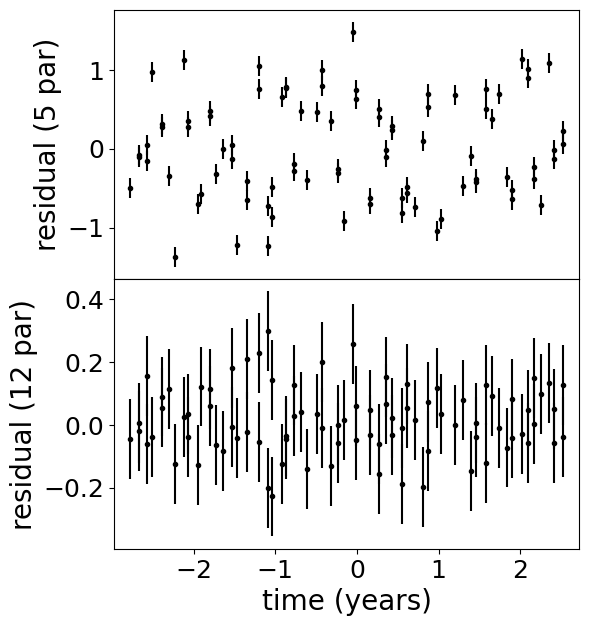

In [7]:
default_fit = direct_results[0]  # the run that omitted the optimizer argument
period, phi_p, ecc = default_fit["period"], default_fit["phi_p"], default_fit["ecc"]

print(f"Using default optimizer result: {default_fit['optimizer']}")
print(f"P = {period:.5f} d, phi_p = {phi_p:.5f}, e = {ecc:.4f}")

gaiamock.plot_residuals(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    theta_array=np.array([period, phi_p, ecc]),
    c_funcs=c_funcs,
)
plt.show()

The same comparison can be useful to make manually, because it gives direct access to the residual arrays and chi2 values for further diagnostics.

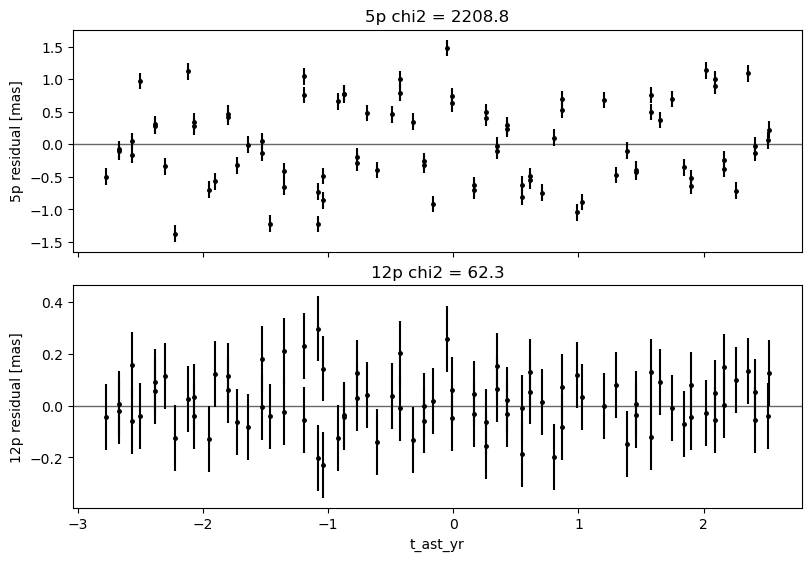

In [8]:
def fit_5p_model(t_ast_yr, psi, plx_factor, ast_obs, ast_err):
    design = np.vstack([
        np.sin(psi),
        t_ast_yr * np.sin(psi),
        np.cos(psi),
        t_ast_yr * np.cos(psi),
        plx_factor,
    ]).T
    weights = 1.0 / ast_err**2
    lhs = design.T @ (weights[:, None] * design)
    rhs = design.T @ (weights * ast_obs)
    mu = np.linalg.solve(lhs, rhs)
    model = design @ mu
    return model, mu

model_5p, mu_5p_manual = fit_5p_model(t_ast_yr, psi, plx_factor, ast_obs, ast_err)
model_12p = gaiamock.get_residuals_12par_solution(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    theta_array=np.array([period, phi_p, ecc]),
    c_funcs=c_funcs,
)

resid_5p = (ast_obs - model_5p) / ast_err
resid_12p = (ast_obs - model_12p) / ast_err
chi2_5p = np.sum(resid_5p**2)
chi2_12p = np.sum(resid_12p**2)

fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True, constrained_layout=True)
axes[0].axhline(0, color="0.4", lw=1)
axes[0].errorbar(t_ast_yr, ast_obs - model_5p, yerr=ast_err, fmt="k.", ms=5)
axes[0].set_ylabel("5p residual [mas]")
axes[0].set_title(f"5p chi2 = {chi2_5p:.1f}")
axes[1].axhline(0, color="0.4", lw=1)
axes[1].errorbar(t_ast_yr, ast_obs - model_12p, yerr=ast_err, fmt="k.", ms=5)
axes[1].set_xlabel("t_ast_yr")
axes[1].set_ylabel("12p residual [mas]")
axes[1].set_title(f"12p chi2 = {chi2_12p:.1f}")
plt.show()

## Plot the fitted orbit

The Thiele-Innes coefficients describe the projected sky-plane photocenter orbit. `plot_2d_orbit_and_residuals` shows that orbit together with the along-scan residual displacements.


a0 = 1.229 mas
Omega = 63.6 deg, omega = 185.8 deg, inc = 66.0 deg


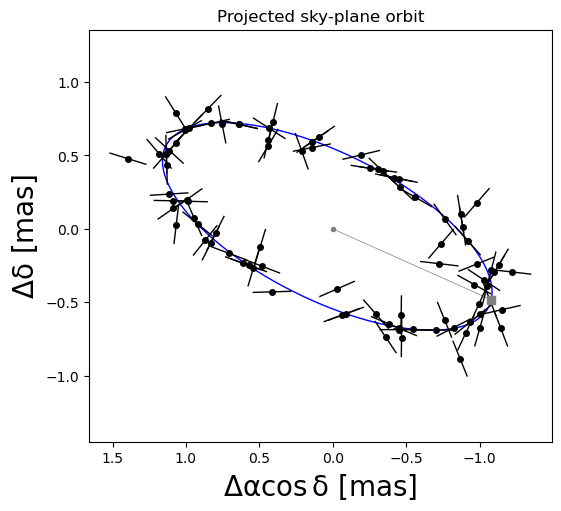

In [9]:
chi2, mu_linear = gaiamock.get_astrometric_chi2(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    P=period,
    phi_p=phi_p,
    ecc=ecc,
    c_funcs=c_funcs,
    reject_outlier=True,
)
ra_off, pmra, dec_off, pmdec, plx, B, G, A, F = mu_linear
Tp = phi_p * period / (2 * np.pi)

a0_mas, Omega, w_fit, inc = gaiamock.get_Campbell_elements(A=A, B=B, F=F, G=G)
print(f"a0 = {a0_mas:.3f} mas")
print(f"Omega = {np.degrees(Omega):.1f} deg, omega = {np.degrees(w_fit):.1f} deg, inc = {np.degrees(inc):.1f} deg")

fig, ax = plt.subplots(figsize=(5.5, 5.0), constrained_layout=True)
gaiamock.plot_2d_orbit_and_residuals(
    t_ast_yr=t_ast_yr,
    psi=psi,
    plx_factor=plx_factor,
    ast_obs=ast_obs,
    ast_err=ast_err,
    period=period,
    ecc=ecc,
    Tp=Tp,
    delta_ra=ra_off,
    delta_dec=dec_off,
    parallax=plx,
    pmra=pmra,
    pmdec=pmdec,
    data_release=mock_truth["data_release"],
    A=A,
    B=B,
    F=F,
    G=G,
    c_funcs=c_funcs,
    ax=ax,
)
ax.set_title("Projected sky-plane orbit")
ax.axis("equal")
plt.show()


## Practical recommendations

- For production binary searches, omit `optimizer` or use `optimizer="periodogram_multistart_v2"`. This selects the broader search in both the direct fitter and the full astrometric cascade.
- Pass `optimizer="periodogram_multistart"` for the previous search. Its `_full` variant provides a denser version of that strategy, and `_gsl` provides the original χ² evaluation for numerical and timing comparisons.
- Use `multistart` or `annealing` as alternative searches when investigating difficult cases. Compare χ² with the same data, bounds, and outlier policy; no optimizer is guaranteed to win on every source.
- Treat fits at the period or eccentricity boundaries with care, and inspect residuals and competing minima before interpreting an orbit. Finding a lower χ² alone does not establish that a fitted orbit is physical.
- Set `reject_outlier=True` only when you want each likelihood evaluation to ignore the single worst epoch. The fitter's default is `False`; the examples here explicitly enable it to demonstrate that option.
- For high-throughput runs, load `c_funcs = gaiamock.read_in_C_functions()` once and reuse it.
